In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
### Load The Dataset
---

In [2]:
df = pd.read_csv("student_performance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


---
### Identify The Number Of Rows And Columns
---

In [4]:
print("Number of rows: ",df.shape[0])
print("Number of columns: ",df.shape[1])

Number of rows:  1000
Number of columns:  12


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']


---
### Analyze The Dataset Structure And Datatypes

---

In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    str    
 2   Gender                     952 non-null    str    
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    str    
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(1), str(3)
memory usage: 115.5+ KB


In [7]:
print("Data types of each column:")
print(df.dtypes)

Data types of each column:
StudentID                    float64
Name                             str
Gender                           str
AttendanceRate               float64
StudyHoursPerWeek            float64
PreviousGrade                float64
ExtracurricularActivities    float64
ParentalSupport                  str
FinalGrade                   float64
Study Hours                  float64
Attendance (%)               float64
Online Classes Taken          object
dtype: object


In [8]:
print("Statistical summary:")
print(df.describe())

Statistical summary:
         StudentID  AttendanceRate  StudyHoursPerWeek  PreviousGrade  \
count   960.000000      960.000000         950.000000     967.000000   
mean   5416.019792       85.510417          17.630526      77.598759   
std    2653.748319        7.332125           6.272132      10.006640   
min       1.000000       70.000000           8.000000      60.000000   
25%    3113.500000       82.000000          12.000000      70.000000   
50%    5396.500000       88.000000          18.000000      78.000000   
75%    7754.750000       91.000000          22.000000      86.000000   
max    9998.000000       95.000000          30.000000      90.000000   

       ExtracurricularActivities  FinalGrade  Study Hours  Attendance (%)  
count                 957.000000  960.000000   976.000000      959.000000  
mean                    1.520376   80.030208     2.406967       77.248175  
std                     1.046439    9.493652     1.620267       19.298148  
min                     0.

---
### Check For Missing Values
---

In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
StudentID                    40
Name                         34
Gender                       48
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
ParentalSupport              22
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
Online Classes Taken         25
dtype: int64


In [10]:
print("Total missing values:")
print(df.isnull().sum().sum())

Total missing values:
440


---
### Identify And Remove Duplicates
---

In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


---
### Perform Basic Data Cleaning
---

In [12]:
df_clean = df.copy()

In [13]:
numeric_cols = [
    "StudentID",
    "AttendanceRate",
    "StudyHoursPerWeek",
    "PreviousGrade",
    "ExtracurricularActivities",
    "FinalGrade",
    "Study Hours",
    "Attendance (%)"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

In [14]:
df_clean.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [15]:
# Attendance must be between 0 and 100
for col in ["AttendanceRate", "Attendance (%)"]:
    df_clean.loc[
        (df_clean[col] < 0) | (df_clean[col] > 100),
        col
    ] = np.nan

# Study hours cannot be negative
for col in ["StudyHoursPerWeek", "Study Hours"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Grades cannot be negative
for col in ["PreviousGrade", "FinalGrade"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Student IDs should be positive
df_clean.loc[df_clean["StudentID"] <= 0, "StudentID"] = np.nan

# Activity count cannot be negative
df_clean.loc[
    df_clean["ExtracurricularActivities"] < 0,
    "ExtracurricularActivities"
] = np.nan

In [16]:
df_clean.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [17]:
for col in numeric_cols:
    if col != "StudentID":
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

In [18]:
df_clean["Name"] = df_clean["Name"].fillna("Unknown")


In [19]:
categorical_cols = [
    "Gender",
    "ParentalSupport",
    "Online Classes Taken"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode().iloc[0]
        )
    else:
        df_clean[col] = df_clean[col].fillna("Unknown")

In [20]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
StudentID                    40
Name                          0
Gender                        0
AttendanceRate                0
StudyHoursPerWeek             0
PreviousGrade                 0
ExtracurricularActivities     0
ParentalSupport               0
FinalGrade                    0
Study Hours                   0
Attendance (%)                0
Online Classes Taken          0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (1000, 12)


---
### Generate Basic Statistical Insights
---

In [21]:
print("Statistical summary:")
print(df_clean.describe())

print("\nAverage final grade:")
print(round(df_clean["FinalGrade"].mean(), 2))

print("\nHighest final grade:")
print(df_clean["FinalGrade"].max())

print("\nLowest final grade:")
print(df_clean["FinalGrade"].min())

print("\nAverage weekly study hours:")
print(round(df_clean["StudyHoursPerWeek"].mean(), 2))

print("\nAverage attendance rate:")
print(round(df_clean["AttendanceRate"].mean(), 2))

Statistical summary:
         StudentID  AttendanceRate  StudyHoursPerWeek  PreviousGrade  \
count   960.000000     1000.000000        1000.000000    1000.000000   
mean   5416.019792       85.610000          17.649000      77.612000   
std    2653.748319        7.200399           6.113688       9.840238   
min       1.000000       70.000000           8.000000      60.000000   
25%    3113.500000       82.000000          12.000000      70.000000   
50%    5396.500000       88.000000          18.000000      78.000000   
75%    7754.750000       91.000000          22.000000      86.000000   
max    9998.000000       95.000000          30.000000      90.000000   

       ExtracurricularActivities   FinalGrade  Study Hours  Attendance (%)  
count                1000.000000  1000.000000  1000.000000     1000.000000  
mean                    1.498000    80.029000     2.484200       75.957000  
std                     1.029104     9.301649     1.416805       14.307825  
min                   

---
### Create Data Visualizations
---

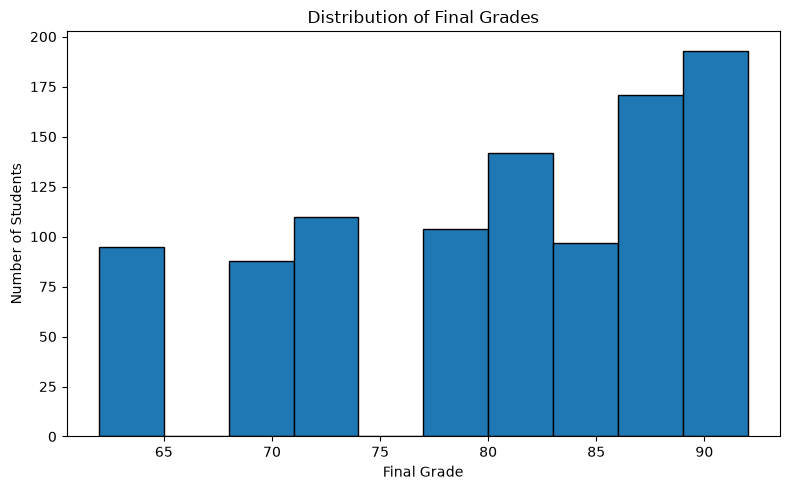

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["FinalGrade"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig("final_grade_distribution.png")
plt.show()

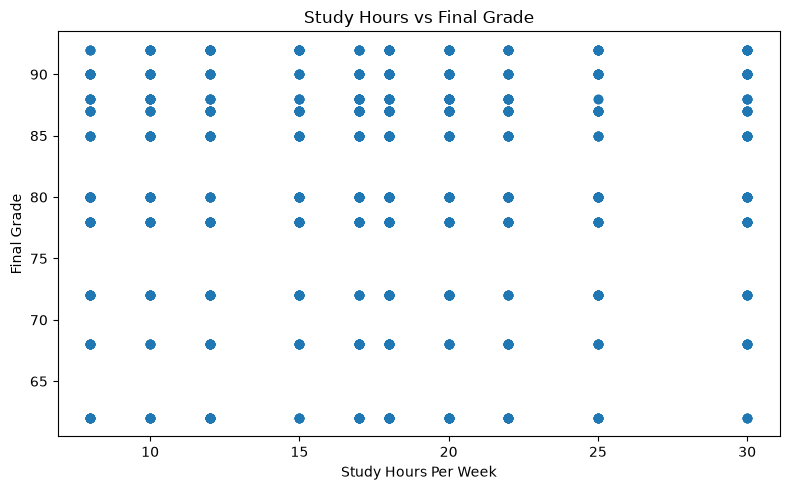

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["StudyHoursPerWeek"],
    df_clean["FinalGrade"]
)

plt.title("Study Hours vs Final Grade")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Final Grade")
plt.tight_layout()
plt.savefig("study_hours_vs_grade.png")
plt.show()

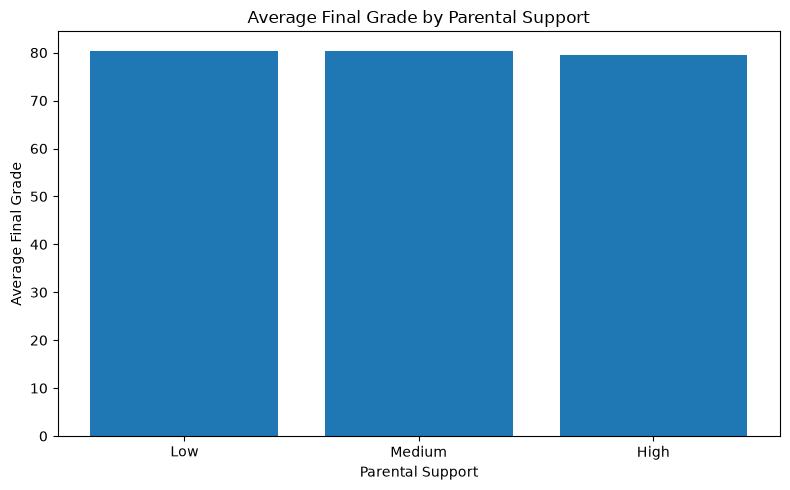

In [24]:
avg_grade = (
    df_clean.groupby("ParentalSupport")["FinalGrade"]
    .mean()
    .reindex(["Low", "Medium", "High"])
    .dropna()
)

plt.figure(figsize=(8, 5))

plt.bar(avg_grade.index, avg_grade.values)
plt.title("Average Final Grade by Parental Support")
plt.xlabel("Parental Support")
plt.ylabel("Average Final Grade")
plt.tight_layout()
plt.savefig("parental_support_vs_grade.png")
plt.show()

---
### Save Cleaned Dataset
---

In [25]:
df_clean.to_csv("student_performance_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
